# 🔬 Benchmark Komprehensif: Metode Transformasi Sinyal 1D ke Citra 2D (dan Inversinya) pada EEG

Notebook ini membandingkan secara kuantitatif dan visual **11 metode transformasi sinyal 1D $\leftrightarrow$ citra 2D** yang dirangkum pada dokumen `METODE_TRANSFORMASI_SINYAL_KE_CITRA.md` menggunakan **100 epoch sinyal EEG nyata** dari `Dataset/EOG` dan `Dataset/EMG` ($N=512$, `float32`).

### 📋 Daftar Metode yang Diuji:
- **Rumpun 1 — Time-Frequency Representations:**
  1. `STFT Mag + Griffin-Lim` (Spektrogram magnitudo klasik, fase dibuang $\to$ estimasi fase iteratif)
  2. `STFT Complex (R+I+L)` (Real + Imag + Length tensor `.npy` $\to$ ISTFT)
  3. `CWT Scalogram (Morlet)` (Continuous Wavelet Transform 32 skala $\to$ aproksimasi ICWT)
  4. `SWT 2D Coeffs (Haar 4L)` (Stationary Wavelet Transform 4 level $\to$ Exact ISWT)
- **Rumpun 2 — Dynamic Fields & Ruang Geometri ($N \times N$):**
  5. `GASF ([0,1] Best-Case)` (Gramian Angular Summation Field $512\times 512$)
  6. `MTF (Markov Field)` (Markov Transition Field $512\times 512$, non-reversibel)
  7. `Recurrence Plot (RP)` (Matriks jarak ruang fase $512\times 512$, non-reversibel)
- **Rumpun 4 — Spatial Folding & Space-Filling Curves:**
  8. `Raster Grayscale 8-bit PNG` (Kuantisasi `uint8` 0..255 seperti Mashhadi et al.)
  9. `Raster RGBA PNG` (IEEE 754 Bit-Packing pada pemindaian raster biasa)
  10. `Morton/Z-Order RGBA PNG` (IEEE 754 Bit-Packing pada kurva Z-Order)
- **Rumpun 5 — Metode Penelitian Anda:**
  11. `Hilbert RGBA PNG (Anda)` (Kurva Hilbert $32\times 32$ + IEEE 754 Bit-Packing + *self-contained metadata*)

*(Catatan: EEG Topomap / Azimuthal Projection tidak disertakan dalam eksekusi karena mensyaratkan multi-kanal 3D elektroda kulit kepala dan bersifat non-reversibel).*


In [1]:
from __future__ import annotations

import io
import time
from dataclasses import dataclass
from functools import lru_cache
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from scipy import signal as sp_signal

from hilbert_png_codec import (
    decode_hilbert_png,
    encode_hilbert_png,
    hilbert_indices,
    rgba_array_to_hilbert_grid,
)

# Konfigurasi tampilan grafik & direktori output
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

OUT_DIR = Path("comparison_outputs")
OUT_DIR.mkdir(exist_ok=True)
print(f"Setup selesai. Direktori output: {OUT_DIR.resolve()}")


Setup selesai. Direktori output: D:\Tsaqib\comparison_outputs


## 1. Utilitas Koordinat Spatial Folding & Metrik Koherensi Spasial 2D

Bagian ini mendefinisikan pemetaan koordinat untuk **Raster**, **Morton (Z-Order)**, dan **Hilbert**, serta metrik:
- **Jarak Langkah Temporal (`Mean_Step_L1`, `Max_Jump_L1`)**: Jarak Manhattan $|r_{t+1}-r_t| + |c_{t+1}-c_t|$ antar sampel waktu berurutan pada grid 2D. Semakin mendekati `1.0`, semakin utuh kontinuitas temporalnya.
- **Korelasi Tetangga 2D (`Spatial_Neighbor_Corr_2D`)**: Korelasi Pearson antar piksel aktif dengan tetangga 4-arahnya (atas/bawah/kiri/kanan).
- **Normalized 2D Total Variation (`Spatial_Norm_TV_2D`)**: Kehalusan transisi antar piksel bertetangga (lebih kecil = lebih halus untuk kernel konvolusi `3x3`).


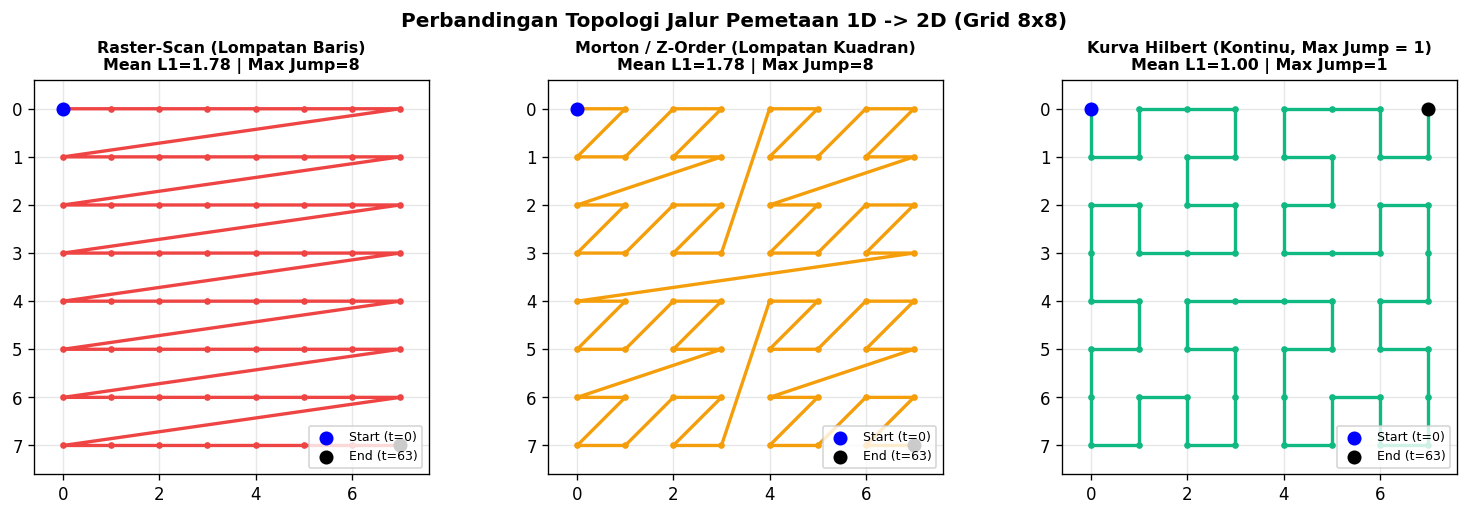

In [2]:
@lru_cache(maxsize=8)
def raster_indices(img_size: int = 32) -> tuple[np.ndarray, np.ndarray]:
    """Koordinat (rows, cols) pemindaian raster baris demi baris."""
    idx = np.arange(img_size * img_size, dtype=np.int64)
    return idx // img_size, idx % img_size


def _morton_d2xy(d: int) -> tuple[int, int]:
    """Memisahkan bit genap/ganjil dari indeks Morton (Z-order) ke koordinat (x, y)."""
    x = 0
    y = 0
    for bit in range(16):
        x |= ((d >> (2 * bit)) & 1) << bit
        y |= ((d >> (2 * bit + 1)) & 1) << bit
    return x, y


@lru_cache(maxsize=8)
def morton_indices(img_size: int = 32) -> tuple[np.ndarray, np.ndarray]:
    """Koordinat (rows, cols) kurva Morton / Z-Order."""
    coords = [_morton_d2xy(d) for d in range(img_size * img_size)]
    xs, ys = zip(*coords)
    return np.asarray(ys, dtype=np.int64), np.asarray(xs, dtype=np.int64)


def compute_curve_locality(rows: np.ndarray, cols: np.ndarray, n: int) -> tuple[float, int]:
    """Menghitung rata-rata & maksimum jarak Manhattan L1 antar sampel waktu berurutan (t, t+1)."""
    dr = np.abs(np.diff(rows[:n]))
    dc = np.abs(np.diff(cols[:n]))
    l1 = dr + dc
    return float(np.mean(l1)), int(np.max(l1))


def compute_2d_spatial_coherence(plane: np.ndarray, mask: np.ndarray | None = None) -> tuple[float, float]:
    """Mengukur korelasi tetangga 4-arah & Normalized Total Variation pada citra 2D."""
    H, W = plane.shape
    mask = np.ones((H, W), dtype=bool) if mask is None else mask.astype(bool)

    pairs_a, pairs_b = [], []
    h_valid = mask[:, :-1] & mask[:, 1:]
    if np.any(h_valid):
        pairs_a.append(plane[:, :-1][h_valid])
        pairs_b.append(plane[:, 1:][h_valid])

    v_valid = mask[:-1, :] & mask[1:, :]
    if np.any(v_valid):
        pairs_a.append(plane[:-1, :][v_valid])
        pairs_b.append(plane[1:, :][v_valid])

    if not pairs_a:
        return float("nan"), float("nan")

    a = np.concatenate(pairs_a).astype(np.float64)
    b = np.concatenate(pairs_b).astype(np.float64)
    corr = 0.0 if (np.std(a) < 1e-12 or np.std(b) < 1e-12) else float(np.corrcoef(a, b)[0, 1])

    sig_std = float(np.std(plane[mask].astype(np.float64))) + 1e-12
    norm_tv = float(np.mean(np.abs(a - b)) / sig_std)
    return corr, norm_tv


# Visualisasi perbandingan jalur pemetaan (Grid 8x8 agar lintasan mudah dilihat)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
curves_demo = [
    ("Raster-Scan (Lompatan Baris)", raster_indices, "#ef4444"),
    ("Morton / Z-Order (Lompatan Kuadran)", morton_indices, "#f59e0b"),
    ("Kurva Hilbert (Kontinu, Max Jump = 1)", hilbert_indices, "#10b981"),
]
for ax, (title, fn, color) in zip(axes, curves_demo):
    r8, c8 = fn(8)
    m_l1, mx_l1 = compute_curve_locality(r8, c8, 64)
    ax.plot(c8, r8, color=color, lw=2.0, marker="o", markersize=3)
    ax.scatter([c8[0]], [r8[0]], color="blue", s=55, zorder=5, label="Start (t=0)")
    ax.scatter([c8[-1]], [r8[-1]], color="black", s=55, zorder=5, label="End (t=63)")
    ax.set_title(f"{title}\nMean L1={m_l1:.2f} | Max Jump={mx_l1}", fontsize=9.5, fontweight="bold")
    ax.set_xlim(-0.6, 7.6)
    ax.set_ylim(7.6, -0.6)
    ax.set_aspect("equal")
    ax.legend(fontsize=7.5, loc="lower right")
plt.suptitle("Perbandingan Topologi Jalur Pemetaan 1D -> 2D (Grid 8x8)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## 2. Implementasi 11 Metode Transformasi Signal $\leftrightarrow$ Image

Setiap fungsi mengembalikan:
- `vis_2d`: representasi citra 2D untuk visualisasi,
- `plane_for_coherence` & `mask`: bidang 2D untuk mengukur koherensi tetangga,
- `rec`: sinyal rekonstruksi 1D (`None` jika metode non-reversibel),
- `shape`, `disk_bytes`, `t_enc_ms`, dan `t_dec_ms`.


In [3]:
# --- RUMPUN 1: TIME-FREQUENCY ---

def stft_mag_gl_roundtrip(sig: np.ndarray, nperseg: int = 64, noverlap: int = 48, n_iter: int = 32):
    """STFT Magnitude Spectrogram (fase dibuang) -> Rekonstruksi via Griffin-Lim + ISTFT."""
    t0 = time.perf_counter()
    _, _, Z = sp_signal.stft(sig, nperseg=nperseg, noverlap=noverlap, window="hann")
    mag = np.abs(Z).astype(np.float32)

    buf = io.BytesIO()
    np.save(buf, mag)
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    buf.seek(0)
    mag_loaded = np.load(buf)
    rng = np.random.default_rng(42)
    phase = np.exp(1j * rng.uniform(-np.pi, np.pi, size=mag_loaded.shape))
    est = mag_loaded * phase
    for _ in range(n_iter):
        _, x_est = sp_signal.istft(est, nperseg=nperseg, noverlap=noverlap, window="hann")
        x_est = x_est[: sig.size]
        _, _, Z_est = sp_signal.stft(x_est, nperseg=nperseg, noverlap=noverlap, window="hann")
        est = mag_loaded * np.exp(1j * np.angle(Z_est))
    _, rec = sp_signal.istft(est, nperseg=nperseg, noverlap=noverlap, window="hann")
    rec = rec[: sig.size].astype(np.float32)
    t_dec = (time.perf_counter() - t1) * 1000.0

    return {
        "vis_2d": np.log1p(mag),
        "plane_for_coherence": mag,
        "mask": None,
        "rec": rec,
        "shape": mag.shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": t_dec,
    }


def stft_complex_roundtrip(sig: np.ndarray, nperseg: int = 64, noverlap: int = 48):
    """Complex STFT (Real + Imag + Length planes) -> ISTFT."""
    t0 = time.perf_counter()
    _, _, Z = sp_signal.stft(sig, nperseg=nperseg, noverlap=noverlap, window="hann")
    len_plane = np.full(Z.shape, float(sig.size), dtype=np.float32)
    tensor = np.stack([Z.real.astype(np.float32), Z.imag.astype(np.float32), len_plane], axis=0)
    buf = io.BytesIO()
    np.save(buf, tensor)
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    buf.seek(0)
    loaded = np.load(buf)
    Z_rec = loaded[0] + 1j * loaded[1]
    n_orig = int(round(float(loaded[2, 0, 0])))
    _, rec = sp_signal.istft(Z_rec, nperseg=nperseg, noverlap=noverlap, window="hann")
    rec = rec[:n_orig].astype(np.float32)
    t_dec = (time.perf_counter() - t1) * 1000.0

    return {
        "vis_2d": np.log1p(np.abs(Z)),
        "plane_for_coherence": np.abs(Z).astype(np.float32),
        "mask": None,
        "rec": rec,
        "shape": tensor.shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": t_dec,
    }


def _morlet_cwt_fft(sig: np.ndarray, scales: np.ndarray, w0: float = 6.0) -> np.ndarray:
    """Continuous Wavelet Transform (analytic Morlet) berbasis FFT."""
    n = sig.size
    freqs = 2.0 * np.pi * np.fft.fftfreq(n)
    sig_fft = np.fft.fft(sig.astype(np.float64))
    W = np.empty((scales.size, n), dtype=np.complex128)
    for i, s in enumerate(scales):
        psi_hat = (np.pi ** -0.25) * np.exp(-0.5 * (s * freqs - w0) ** 2) * (freqs > 0)
        W[i] = np.fft.ifft(sig_fft * np.sqrt(s) * psi_hat)
    return W


def cwt_morlet_roundtrip(sig: np.ndarray, n_scales: int = 32):
    """CWT Morlet Scalogram -> Rekonstruksi aproksimasi via ICWT."""
    t0 = time.perf_counter()
    scales = np.geomspace(1.0, 64.0, num=n_scales)
    W = _morlet_cwt_fft(sig, scales, w0=6.0)
    scalogram = np.abs(W).astype(np.float32)
    W_real = W.real.astype(np.float32)
    buf = io.BytesIO()
    np.save(buf, W_real)
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    buf.seek(0)
    W_loaded = np.load(buf).astype(np.float64)
    dj = np.log2(scales[1] / scales[0])
    C_delta = 0.776
    psi0 = np.pi ** -0.25
    rec_raw = (dj / (C_delta * psi0)) * np.sum(W_loaded / np.sqrt(scales)[:, None], axis=0)
    gain = float(np.dot(sig.astype(np.float64), rec_raw)) / (float(np.dot(rec_raw, rec_raw)) + 1e-12)
    rec = (rec_raw * gain).astype(np.float32)
    t_dec = (time.perf_counter() - t1) * 1000.0

    return {
        "vis_2d": scalogram,
        "plane_for_coherence": scalogram,
        "mask": None,
        "rec": rec,
        "shape": W_real.shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": t_dec,
    }


def _haar_swt(sig: np.ndarray, levels: int = 4) -> np.ndarray:
    """Stationary Wavelet Transform (Haar, shift-invariant) pure NumPy."""
    cA = sig.astype(np.float32).copy()
    inv_sqrt2 = np.float32(1.0 / np.sqrt(2.0))
    details = []
    for j in range(levels):
        step = 1 << j
        shifted = np.roll(cA, -step)
        cD = (cA - shifted) * inv_sqrt2
        cA = (cA + shifted) * inv_sqrt2
        details.append(cD)
    return np.stack([cA] + details[::-1], axis=0)


def _haar_iswt(coeffs: np.ndarray) -> np.ndarray:
    """Inverse Stationary Wavelet Transform (Haar) eksak secara numerik."""
    inv_sqrt2 = np.float32(1.0 / np.sqrt(2.0))
    cA = coeffs[0].astype(np.float32).copy()
    details_rev = coeffs[1:]
    levels = details_rev.shape[0]
    for idx in range(levels):
        j = levels - 1 - idx
        step = 1 << j
        cD = details_rev[idx]
        est1 = (cA + cD) * inv_sqrt2
        est2 = (np.roll(cA, step) - np.roll(cD, step)) * inv_sqrt2
        cA = np.float32(0.5) * (est1 + est2)
    return cA


def swt_haar_roundtrip(sig: np.ndarray, levels: int = 4):
    """Stationary Wavelet Transform 2D Coeffs (5 x N) -> Exact Inverse SWT."""
    t0 = time.perf_counter()
    coeffs = _haar_swt(sig, levels=levels)
    buf = io.BytesIO()
    np.save(buf, coeffs)
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    buf.seek(0)
    loaded = np.load(buf)
    rec = _haar_iswt(loaded)
    t_dec = (time.perf_counter() - t1) * 1000.0

    return {
        "vis_2d": coeffs,
        "plane_for_coherence": coeffs,
        "mask": None,
        "rec": rec,
        "shape": coeffs.shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": t_dec,
    }


# --- RUMPUN 2: DYNAMIC FIELDS & GEOMETRI (N x N) ---

def gasf_roundtrip(sig: np.ndarray):
    """Gramian Angular Summation Field (N x N) dengan normalisasi [0, 1] (best-case invertible)."""
    t0 = time.perf_counter()
    x = sig.astype(np.float32)
    xmin, xmax = float(x.min()), float(x.max())
    rng = max(xmax - xmin, 1e-12)
    x_norm = np.clip((x - xmin) / rng, 0.0, 1.0)
    s_term = np.sqrt(np.maximum(0.0, 1.0 - x_norm ** 2))
    gasf = (np.outer(x_norm, x_norm) - np.outer(s_term, s_term)).astype(np.float32)

    buf = io.BytesIO()
    np.save(buf, gasf)
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    buf.seek(0)
    loaded = np.load(buf)
    diag = np.clip(np.diag(loaded), -1.0, 1.0)
    x_norm_rec = np.sqrt(np.maximum(0.0, (diag + 1.0) * 0.5))
    rec = (x_norm_rec * rng + xmin).astype(np.float32)
    t_dec = (time.perf_counter() - t1) * 1000.0

    return {
        "vis_2d": gasf,
        "plane_for_coherence": gasf,
        "mask": None,
        "rec": rec,
        "shape": gasf.shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": t_dec,
    }


def mtf_encode_only(sig: np.ndarray, n_bins: int = 8):
    """Markov Transition Field (N x N) - Non-invertible."""
    t0 = time.perf_counter()
    quantiles = np.quantile(sig, np.linspace(0, 1, n_bins + 1))
    quantiles[-1] += 1e-6
    states = np.clip(np.digitize(sig, quantiles[1:-1]), 0, n_bins - 1)

    W = np.zeros((n_bins, n_bins), dtype=np.float32)
    np.add.at(W, (states[:-1], states[1:]), 1.0)
    W = np.divide(W, np.maximum(W.sum(axis=1, keepdims=True), 1.0))
    mtf = W[states[:, None], states[None, :]].astype(np.float32)

    buf = io.BytesIO()
    np.save(buf, mtf)
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    return {
        "vis_2d": mtf,
        "plane_for_coherence": mtf,
        "mask": None,
        "rec": None,
        "shape": mtf.shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": float("nan"),
    }


def recurrence_plot_encode_only(sig: np.ndarray, eps_ratio: float = 0.25):
    """Recurrence Plot (N x N) - Non-invertible."""
    t0 = time.perf_counter()
    x = sig.astype(np.float32)
    dist = np.abs(x[:, None] - x[None, :])
    eps = eps_ratio * float(np.std(x))
    rp = (dist <= eps).astype(np.uint8)

    buf = io.BytesIO()
    Image.fromarray(rp * 255, mode="L").save(buf, format="PNG")
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    return {
        "vis_2d": rp.astype(np.float32),
        "plane_for_coherence": rp.astype(np.float32),
        "mask": None,
        "rec": None,
        "shape": rp.shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": float("nan"),
    }


# --- RUMPUN 4 & 5: SPATIAL FOLDING & SPACE-FILLING CURVES ---

def raster_gray8_png_roundtrip(sig: np.ndarray, img_size: int = 32):
    """Raster-Scan 8-bit Grayscale PNG (kuantisasi uint8 0..255)."""
    t0 = time.perf_counter()
    n = sig.size
    rows, cols = raster_indices(img_size)
    xmin, xmax = float(sig.min()), float(sig.max())
    rng = max(xmax - xmin, 1e-12)
    q = np.round((sig - xmin) / rng * 255.0).clip(0, 255).astype(np.uint8)

    img_arr = np.zeros((img_size, img_size), dtype=np.uint8)
    img_arr[rows[:n], cols[:n]] = q

    buf = io.BytesIO()
    Image.fromarray(img_arr, mode="L").save(buf, format="PNG")
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    buf.seek(0)
    loaded = np.asarray(Image.open(buf), dtype=np.uint8)
    rec = (loaded[rows[:n], cols[:n]].astype(np.float32) / 255.0) * rng + xmin
    t_dec = (time.perf_counter() - t1) * 1000.0

    plane = np.zeros((img_size, img_size), dtype=np.float32)
    mask = np.zeros((img_size, img_size), dtype=bool)
    plane[rows[:n], cols[:n]] = sig
    mask[rows[:n], cols[:n]] = True

    return {
        "vis_2d": plane,
        "plane_for_coherence": plane,
        "mask": mask,
        "rec": rec,
        "shape": (img_size, img_size),
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": t_dec,
    }


def _generic_sfc_rgba_png_roundtrip(
    sig: np.ndarray,
    index_fn: Callable[[int], tuple[np.ndarray, np.ndarray]],
    img_size: int = 32,
):
    """Helper umum Spatial Folding + IEEE 754 RGBA PNG Bit-Packing."""
    t0 = time.perf_counter()
    sig_c = np.ascontiguousarray(sig, dtype="<f4").reshape(-1)
    n = sig_c.size
    rows, cols = index_fn(img_size)

    rgba = np.zeros((img_size, img_size, 4), dtype=np.uint8)
    rgba[rows[:n], cols[:n]] = sig_c.view(np.uint8).reshape(n, 4)
    rgba[rows[-1], cols[-1]] = np.array([n], dtype="<u4").view(np.uint8)

    buf = io.BytesIO()
    Image.fromarray(rgba, mode="RGBA").save(buf, format="PNG")
    disk_bytes = buf.tell()
    t_enc = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    buf.seek(0)
    loaded = np.asarray(Image.open(buf), dtype=np.uint8)
    n_dec = int(np.ascontiguousarray(loaded[rows[-1], cols[-1]]).view("<u4")[0])
    sig_bytes = np.ascontiguousarray(loaded[rows[:n_dec], cols[:n_dec]])
    rec = sig_bytes.view("<f4").reshape(n_dec)
    t_dec = (time.perf_counter() - t1) * 1000.0

    plane = np.zeros((img_size, img_size), dtype=np.float32)
    mask = np.zeros((img_size, img_size), dtype=bool)
    plane[rows[:n], cols[:n]] = sig_c
    mask[rows[:n], cols[:n]] = True

    return {
        "vis_2d": plane,
        "plane_for_coherence": plane,
        "mask": mask,
        "rec": rec,
        "shape": rgba.shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": t_dec,
    }


def raster_rgba_png_roundtrip(sig: np.ndarray, img_size: int = 32):
    return _generic_sfc_rgba_png_roundtrip(sig, raster_indices, img_size=img_size)


def morton_rgba_png_roundtrip(sig: np.ndarray, img_size: int = 32):
    return _generic_sfc_rgba_png_roundtrip(sig, morton_indices, img_size=img_size)


def hilbert_rgba_png_roundtrip(sig: np.ndarray, img_size: int = 32):
    """Metode Anda: Hilbert Curve + IEEE 754 RGBA PNG Bit-Packing."""
    t0 = time.perf_counter()
    buf = io.BytesIO()
    shape = encode_hilbert_png(sig, buf, img_size=img_size)
    disk_bytes = buf.getbuffer().nbytes
    t_enc = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    rec = decode_hilbert_png(buf)
    t_dec = (time.perf_counter() - t1) * 1000.0

    buf.seek(0)
    rgba = np.asarray(Image.open(buf), dtype=np.uint8)
    grid, _ = rgba_array_to_hilbert_grid(rgba)

    return {
        "vis_2d": grid[0],
        "plane_for_coherence": grid[0],
        "mask": grid[1] > 0.5,
        "rec": rec,
        "shape": shape,
        "disk_bytes": disk_bytes,
        "t_enc_ms": t_enc,
        "t_dec_ms": t_dec,
    }

print("Seluruh 11 metode transformasi berhasil didefinisikan.")


Seluruh 11 metode transformasi berhasil didefinisikan.


## 3. Metrik Evaluasi & Eksekusi Benchmark pada 100 Epoch EEG Nyata

Metrik rekonstruksi yang dihitung:
- **Bit-Exact (%)**: Persentase epoch di mana `np.array_equal(orig, rec)` bernilai `True`.
- **Max Abs Error**, **RMSE**, **PRD (%)** (*Percentage Root-mean-square Difference*), **Pearson $r$**, dan **Reconstruction SNR (dB)**.
- Setiap metode menjalani **3x warmup** sebelum pengukuran waktu agar tidak ada bias *cold-start*.


In [4]:
def eval_reconstruction_metrics(orig: np.ndarray, rec: np.ndarray | None) -> dict[str, float | bool]:
    if rec is None:
        return {
            "bit_exact": False,
            "max_abs_err": float("nan"),
            "rmse": float("nan"),
            "mae": float("nan"),
            "prd_pct": float("nan"),
            "pearson_r": float("nan"),
            "snr_rec_db": float("nan"),
        }

    orig_f = orig.astype(np.float64)
    rec_f = rec.astype(np.float64)
    diff = orig_f - rec_f

    bit_exact = bool(np.array_equal(orig.astype(np.float32), rec.astype(np.float32)))
    max_abs = float(np.max(np.abs(diff)))
    mse = float(np.mean(diff ** 2))
    rmse = float(np.sqrt(mse))
    mae = float(np.mean(np.abs(diff)))

    sig_power = float(np.sum(orig_f ** 2))
    err_power = float(np.sum(diff ** 2))
    prd_pct = float(np.sqrt(err_power / (sig_power + 1e-12)) * 100.0)
    snr_db = float("inf") if err_power == 0.0 else float(10.0 * np.log10((sig_power + 1e-12) / err_power))
    r = 0.0 if (np.std(orig_f) < 1e-12 or np.std(rec_f) < 1e-12) else float(np.corrcoef(orig_f, rec_f)[0, 1])

    return {
        "bit_exact": bit_exact,
        "max_abs_err": max_abs,
        "rmse": rmse,
        "mae": mae,
        "prd_pct": prd_pct,
        "pearson_r": r,
        "snr_rec_db": snr_db,
    }


@dataclass
class MethodSpec:
    name: str
    family: str
    fn: Callable[[np.ndarray], dict]
    curve_fn: Callable[[int], tuple[np.ndarray, np.ndarray]] | None
    invertible: str
    container_type: str
    dynamic_len_self_contained: bool


METHODS: list[MethodSpec] = [
    MethodSpec("Hilbert RGBA PNG (Anda)", "R5: Lossless Bit-Packing", hilbert_rgba_png_roundtrip, hilbert_indices, "100% Bit-Exact", "PNG (RGBA)", True),
    MethodSpec("Morton/Z-Order RGBA PNG", "R4: Space-Filling Curve", morton_rgba_png_roundtrip, morton_indices, "100% Bit-Exact", "PNG (RGBA)", True),
    MethodSpec("Raster RGBA PNG", "R4: Spatial Folding", raster_rgba_png_roundtrip, raster_indices, "100% Bit-Exact", "PNG (RGBA)", True),
    MethodSpec("Raster Grayscale 8-bit PNG", "R4: Spatial Folding", raster_gray8_png_roundtrip, raster_indices, "Lossy (Quant 8-bit)", "PNG (L) + min/max", False),
    MethodSpec("SWT 2D Coeffs (Haar 4L)", "R1: Time-Frequency", swt_haar_roundtrip, None, "Float-Exact (ISWT)", ".npy (float32)", False),
    MethodSpec("STFT Complex (R+I+L)", "R1: Time-Frequency", stft_complex_roundtrip, None, "Float-Exact (ISTFT)", ".npy (float32)", True),
    MethodSpec("STFT Mag + Griffin-Lim", "R1: Time-Frequency", stft_mag_gl_roundtrip, None, "Lossy (Phase Lost)", ".npy (float32)", False),
    MethodSpec("CWT Scalogram (Morlet)", "R1: Time-Frequency", cwt_morlet_roundtrip, None, "Lossy (Approx ICWT)", ".npy (float32)", False),
    MethodSpec("GASF ([0,1] Best-Case)", "R2: Dynamic Field NxN", gasf_roundtrip, None, "Semi-Lossy + min/max", ".npy (float32)", False),
    MethodSpec("MTF (Markov Field)", "R2: Dynamic Field NxN", mtf_encode_only, None, "Non-Invertible", ".npy (float32)", False),
    MethodSpec("Recurrence Plot (RP)", "R2: Dynamic Field NxN", recurrence_plot_encode_only, None, "Non-Invertible", "PNG (L binary)", False),
]


def load_eeg_benchmark_signals(n_per_artifact: int = 25) -> list[tuple[str, np.ndarray]]:
    """Memuat sinyal EEG nyata dari Dataset EOG & EMG (clean + noisy SNR -5 dB)."""
    signals: list[tuple[str, np.ndarray]] = []
    for art in ["EOG", "EMG"]:
        clean = np.load(f"Dataset/{art}/clean_eeg_all_epochs.npy")
        syn = np.load(f"Dataset/{art}/linear_synthetic.npy", allow_pickle=True).item()
        noisy = syn[-5]
        for i in range(n_per_artifact):
            signals.append((f"{art}_noisy_{i}", noisy[i].astype(np.float32)))
            signals.append((f"{art}_clean_{i}", clean[i].astype(np.float32)))
    return signals


signals = load_eeg_benchmark_signals(n_per_artifact=25)
n_samples = len(signals)
sig_len = signals[0][1].size
print(f"Menjalankan benchmark pada {n_samples} epoch EEG nyata (N={sig_len}, dtype=float32)...")

rows_summary = []
sample0_outputs: dict[str, dict] = {}

for spec in METHODS:
    # Warmup 3x untuk menghilangkan bias cold-start
    for _ in range(3):
        _ = spec.fn(signals[0][1])

    bit_exact_hits = 0
    max_errs, rmses, prds, corrs, snrs = [], [], [], [], []
    coherences, tvs = [], []
    disk_sizes, t_encs, t_decs = [], [], []
    shape_str, n_pixels_2d, n_elements = "", 0, 0

    for idx, (_, sig) in enumerate(signals):
        res = spec.fn(sig)
        if idx == 0:
            sample0_outputs[spec.name] = res
            shape_str = "x".join(map(str, res["shape"]))
            n_elements = int(np.prod(res["shape"]))
            n_pixels_2d = int(res["vis_2d"].shape[0] * res["vis_2d"].shape[1])

        m = eval_reconstruction_metrics(sig, res["rec"])
        if m["bit_exact"]:
            bit_exact_hits += 1
        max_errs.append(m["max_abs_err"])
        rmses.append(m["rmse"])
        prds.append(m["prd_pct"])
        corrs.append(m["pearson_r"])
        snrs.append(m["snr_rec_db"])

        c2d, tv2d = compute_2d_spatial_coherence(res["plane_for_coherence"], res["mask"])
        coherences.append(c2d)
        tvs.append(tv2d)

        disk_sizes.append(res["disk_bytes"])
        t_encs.append(res["t_enc_ms"])
        t_decs.append(res["t_dec_ms"])

    if spec.curve_fn is not None:
        r_idx, c_idx = spec.curve_fn(32)
        mean_step_l1, max_jump_l1 = compute_curve_locality(r_idx, c_idx, sig_len)
    else:
        mean_step_l1, max_jump_l1 = float("nan"), float("nan")

    valid_snrs = [v for v in snrs if not np.isnan(v)]
    if not valid_snrs:
        mean_snr = float("nan")
    elif all(np.isinf(v) for v in valid_snrs):
        mean_snr = float("inf")
    else:
        finite_snrs = [v for v in valid_snrs if np.isfinite(v)]
        mean_snr = float(np.mean(finite_snrs)) if finite_snrs else float("inf")

    rows_summary.append({
        "Method": spec.name,
        "Family": spec.family,
        "Invertibility": spec.invertible,
        "Container": spec.container_type,
        "Self_Contained_DynLen": spec.dynamic_len_self_contained,
        "Image_Shape": shape_str,
        "Pixels_2D": n_pixels_2d,
        "Expansion_Ratio_vs_N": round(n_pixels_2d / sig_len, 2),
        "Bit_Exact_Pct": round(100.0 * bit_exact_hits / n_samples, 2),
        "Mean_Max_Abs_Err": float(np.nanmean(max_errs)) if not all(np.isnan(max_errs)) else float("nan"),
        "Mean_RMSE": float(np.nanmean(rmses)) if not all(np.isnan(rmses)) else float("nan"),
        "Mean_PRD_Pct": float(np.nanmean(prds)) if not all(np.isnan(prds)) else float("nan"),
        "Mean_Pearson_r": float(np.nanmean(corrs)) if not all(np.isnan(corrs)) else float("nan"),
        "Mean_SNR_Rec_dB": mean_snr,
        "Curve_Mean_Step_L1": mean_step_l1,
        "Curve_Max_Jump_L1": max_jump_l1,
        "Spatial_Neighbor_Corr_2D": float(np.nanmean(coherences)),
        "Spatial_Norm_TV_2D": float(np.nanmean(tvs)),
        "Mean_Disk_Bytes": float(np.mean(disk_sizes)),
        "Mean_Encode_ms": float(np.mean(t_encs)),
        "Mean_Decode_ms": float(np.nanmean(t_decs)) if not all(np.isnan(t_decs)) else float("nan"),
        "Mean_RoundTrip_ms": float(np.mean(t_encs) + np.nanmean(t_decs)) if not all(np.isnan(t_decs)) else float("nan"),
    })

df = pd.DataFrame(rows_summary)
df.to_csv(OUT_DIR / "benchmark_comparison.csv", index=False)
df.to_json(OUT_DIR / "benchmark_comparison.json", orient="records", indent=2)

# Tampilkan tabel rapi
cols_show = [
    "Method", "Image_Shape", "Bit_Exact_Pct", "Mean_PRD_Pct", "Mean_RMSE", "Mean_Pearson_r",
    "Curve_Mean_Step_L1", "Curve_Max_Jump_L1", "Spatial_Neighbor_Corr_2D",
    "Spatial_Norm_TV_2D", "Mean_Disk_Bytes", "Mean_RoundTrip_ms",
]
display(df[cols_show].style.format({
    "Bit_Exact_Pct": "{:.1f}%",
    "Mean_PRD_Pct": "{:.6f}%",
    "Mean_RMSE": "{:.6e}",
    "Mean_Pearson_r": "{:.6f}",
    "Curve_Mean_Step_L1": "{:.3f}",
    "Curve_Max_Jump_L1": "{:.0f}",
    "Spatial_Neighbor_Corr_2D": "{:.4f}",
    "Spatial_Norm_TV_2D": "{:.4f}",
    "Mean_Disk_Bytes": "{:,.1f} B",
    "Mean_RoundTrip_ms": "{:.3f} ms",
}, na_rep="—").highlight_max(subset=["Bit_Exact_Pct", "Mean_RMSE"], color="#d1fae5"))


Menjalankan benchmark pada 100 epoch EEG nyata (N=512, dtype=float32)...


,Method,Image_Shape,Bit_Exact_Pct,Mean_PRD_Pct,Mean_RMSE,Mean_Pearson_r,Curve_Mean_Step_L1,Curve_Max_Jump_L1,Spatial_Neighbor_Corr_2D,Spatial_Norm_TV_2D,Mean_Disk_Bytes,Mean_RoundTrip_ms
0,Hilbert RGBA PNG (Anda),32x32x4,100.0%,0.000000%,0.000000e+00,1.000000,1.000,1,0.5677,0.6234,"2,150.1 B",0.509 ms
1,Morton/Z-Order RGBA PNG,32x32x4,100.0%,0.000000%,0.000000e+00,1.000000,1.910,16,0.5262,0.6749,"2,038.2 B",0.474 ms
2,Raster RGBA PNG,32x32x4,100.0%,0.000000%,0.000000e+00,1.000000,1.910,32,0.4354,0.7225,"2,017.2 B",0.511 ms
3,Raster Grayscale 8-bit PNG,32x32,0.0%,0.684698%,1.049581e-02,0.999976,1.910,32,0.4354,0.7225,539.7 B,0.367 ms
4,SWT 2D Coeffs (Haar 4L),5x512,0.0%,0.000012%,1.834901e-07,1.000000,—,—,0.5876,0.5086,"10,368.0 B",0.485 ms
5,STFT Complex (R+I+L),3x33x33,0.0%,0.000008%,1.212143e-07,1.000000,—,—,0.7824,0.3281,"13,196.0 B",0.774 ms
6,STFT Mag + Griffin-Lim,33x33,0.0%,135.601583%,2.063209e+00,0.035251,—,—,0.7824,0.3281,"4,484.0 B",17.666 ms
7,CWT Scalogram (Morlet),32x512,0.0%,54.720701%,8.584989e-01,0.796730,—,—,0.9371,0.1686,"65,664.0 B",1.756 ms
8,"GASF ([0,1] Best-Case)",512x512,0.0%,0.000095%,1.629690e-06,1.000000,—,—,0.8828,0.2824,"1,048,704.0 B",2.998 ms
9,MTF (Markov Field),512x512,0.0%,—,—,—,—,—,0.6387,0.4445,"1,048,704.0 B",—


## 4. Perbandingan Visual: 1 Sinyal EEG yang Sama pada Seluruh Metode 2D

Plot berikut memperlihatkan bagaimana **1 epoch EEG yang identik** (`EOG Noisy -5 dB, N=512`) direpresentasikan ke dalam bidang citra 2D oleh masing-masing metode.


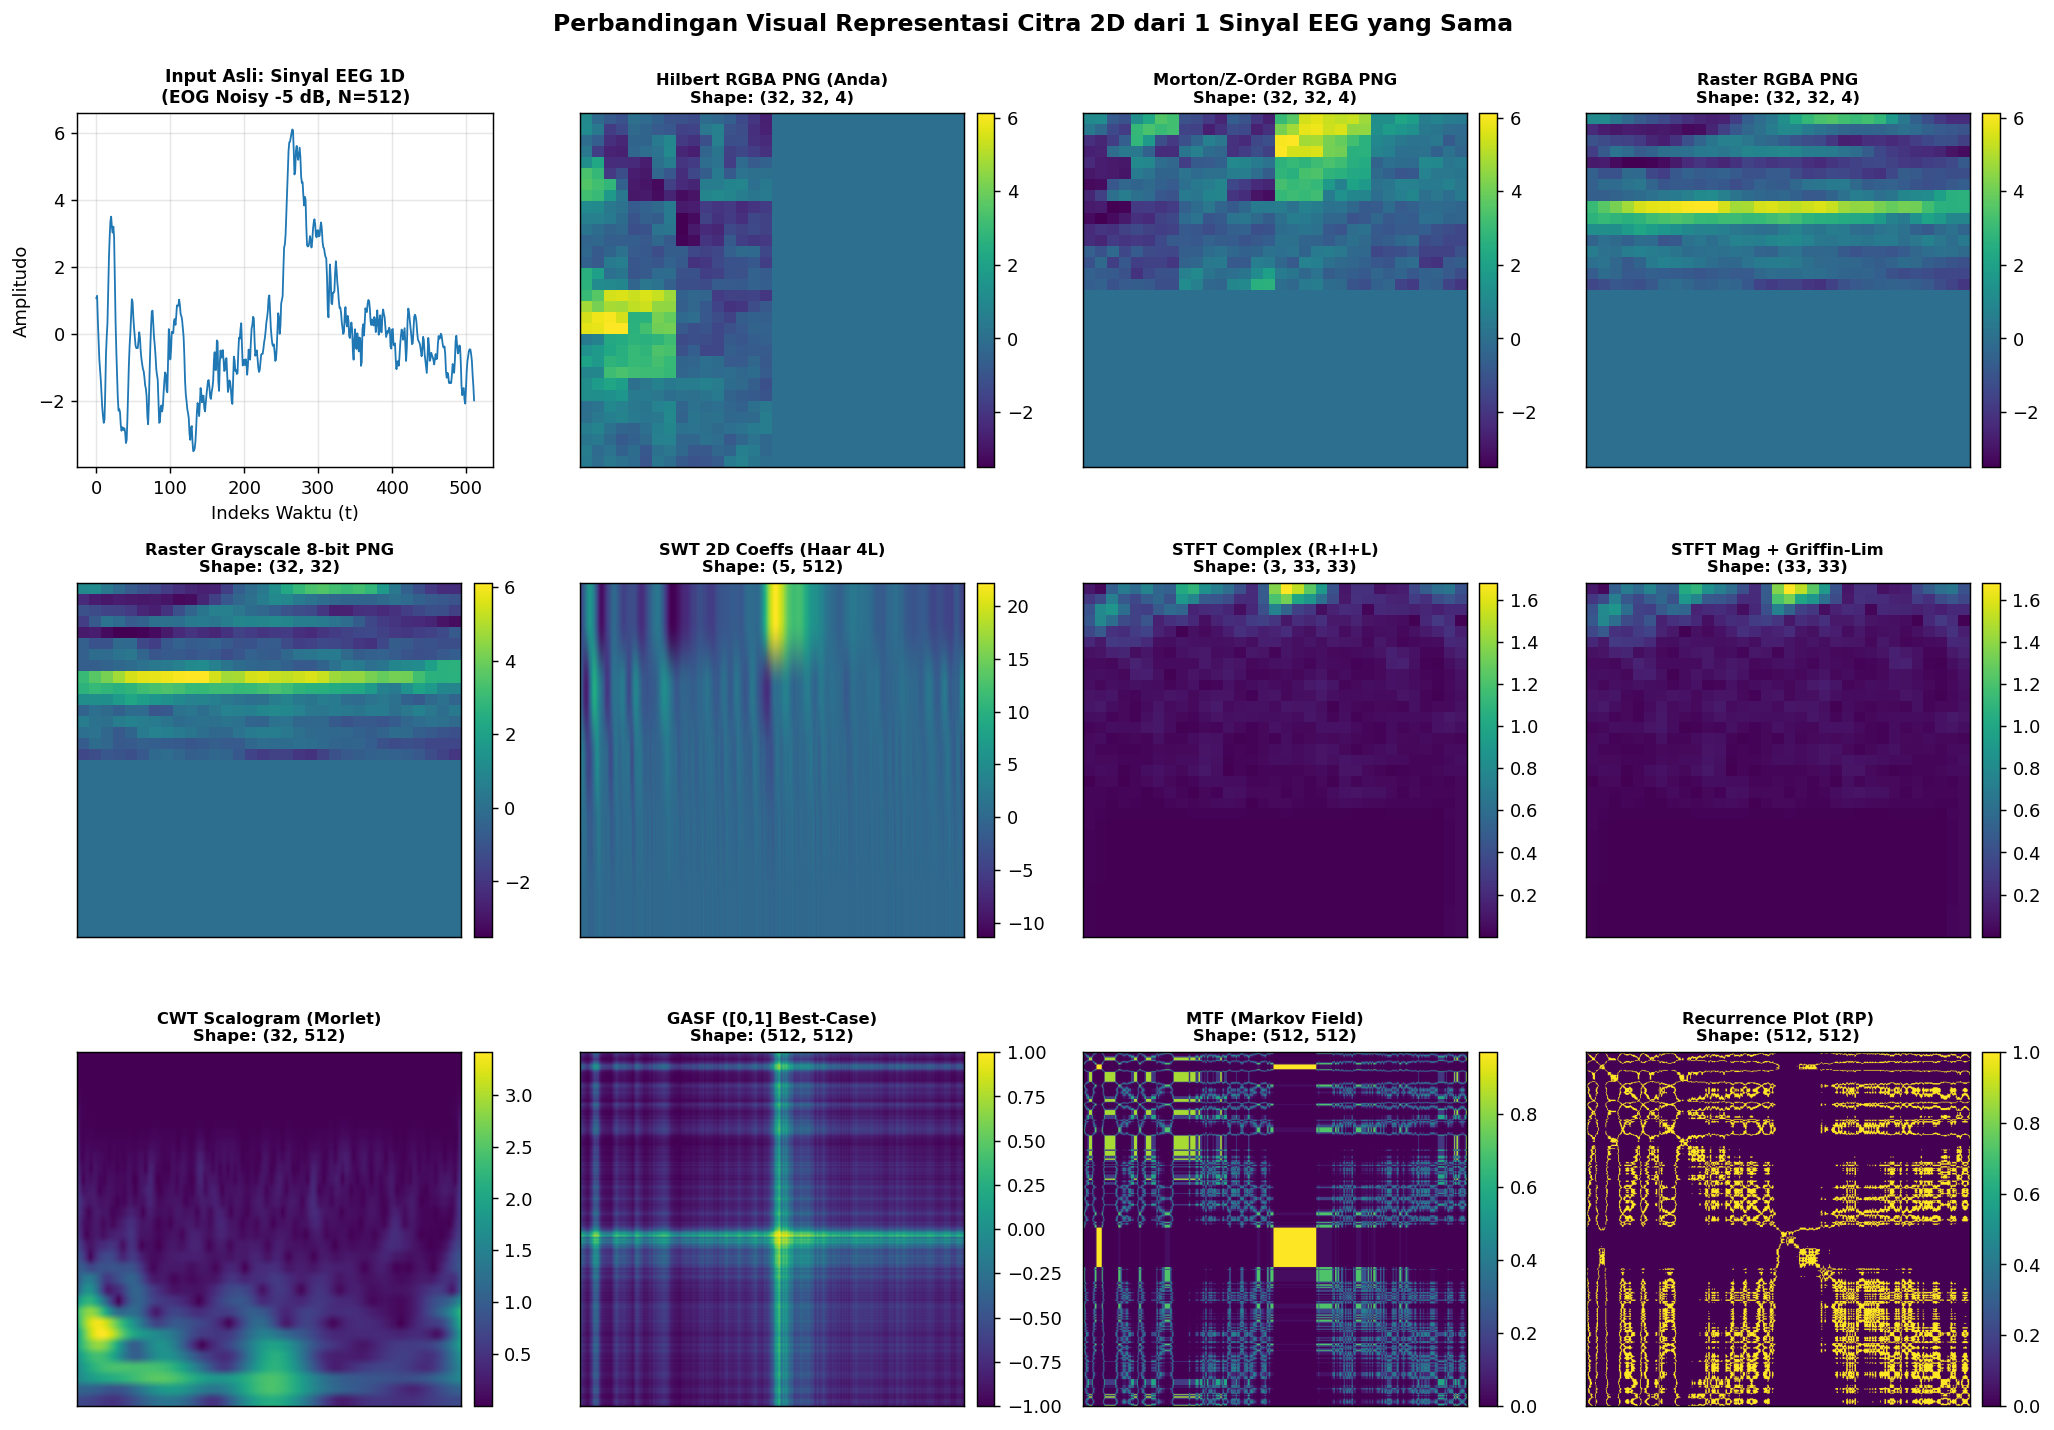

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11), dpi=130)
axes_flat = axes.flatten()

sig0 = signals[0][1]
axes_flat[0].plot(sig0, color="#1f77b4", lw=1.0)
axes_flat[0].set_title("Input Asli: Sinyal EEG 1D\n(EOG Noisy -5 dB, N=512)", fontsize=9.5, fontweight="bold")
axes_flat[0].set_xlabel("Indeks Waktu (t)")
axes_flat[0].set_ylabel("Amplitudo")
axes_flat[0].grid(alpha=0.3)

for i, spec in enumerate(METHODS, start=1):
    ax = axes_flat[i]
    vis = sample0_outputs[spec.name]["vis_2d"]
    im = ax.imshow(vis, aspect="auto", cmap="viridis")
    ax.set_title(f"{spec.name}\nShape: {sample0_outputs[spec.name]['shape']}", fontsize=9, fontweight="bold")
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

plt.suptitle("Perbandingan Visual Representasi Citra 2D dari 1 Sinyal EEG yang Sama", fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(OUT_DIR / "visual_2d_representations.png", bbox_inches="tight")
plt.show()


## 5. Grafik Komparasi 4 Variabel Kunci

Keempat panel di bawah mengevaluasi kekuatan masing-masing metode berdasarkan:
1. **Ketepatan Rekonstruksi (PRD %)** — apakah benar-benar *lossless bit-exact*?
2. **Koherensi Spasial 2D** — seberapa halus & berkorelasi tetangga 2D untuk konvolusi `3x3` pada metode *spatial folding*?
3. **Efisiensi Penyimpanan Disk (Bytes)** — ukuran file per epoch EEG.
4. **Kompaknya Dimensi Citra (Piksel 2D)** — beban memori & FLOPs jika masuk ke jaringan CNN/U-Net 2D.


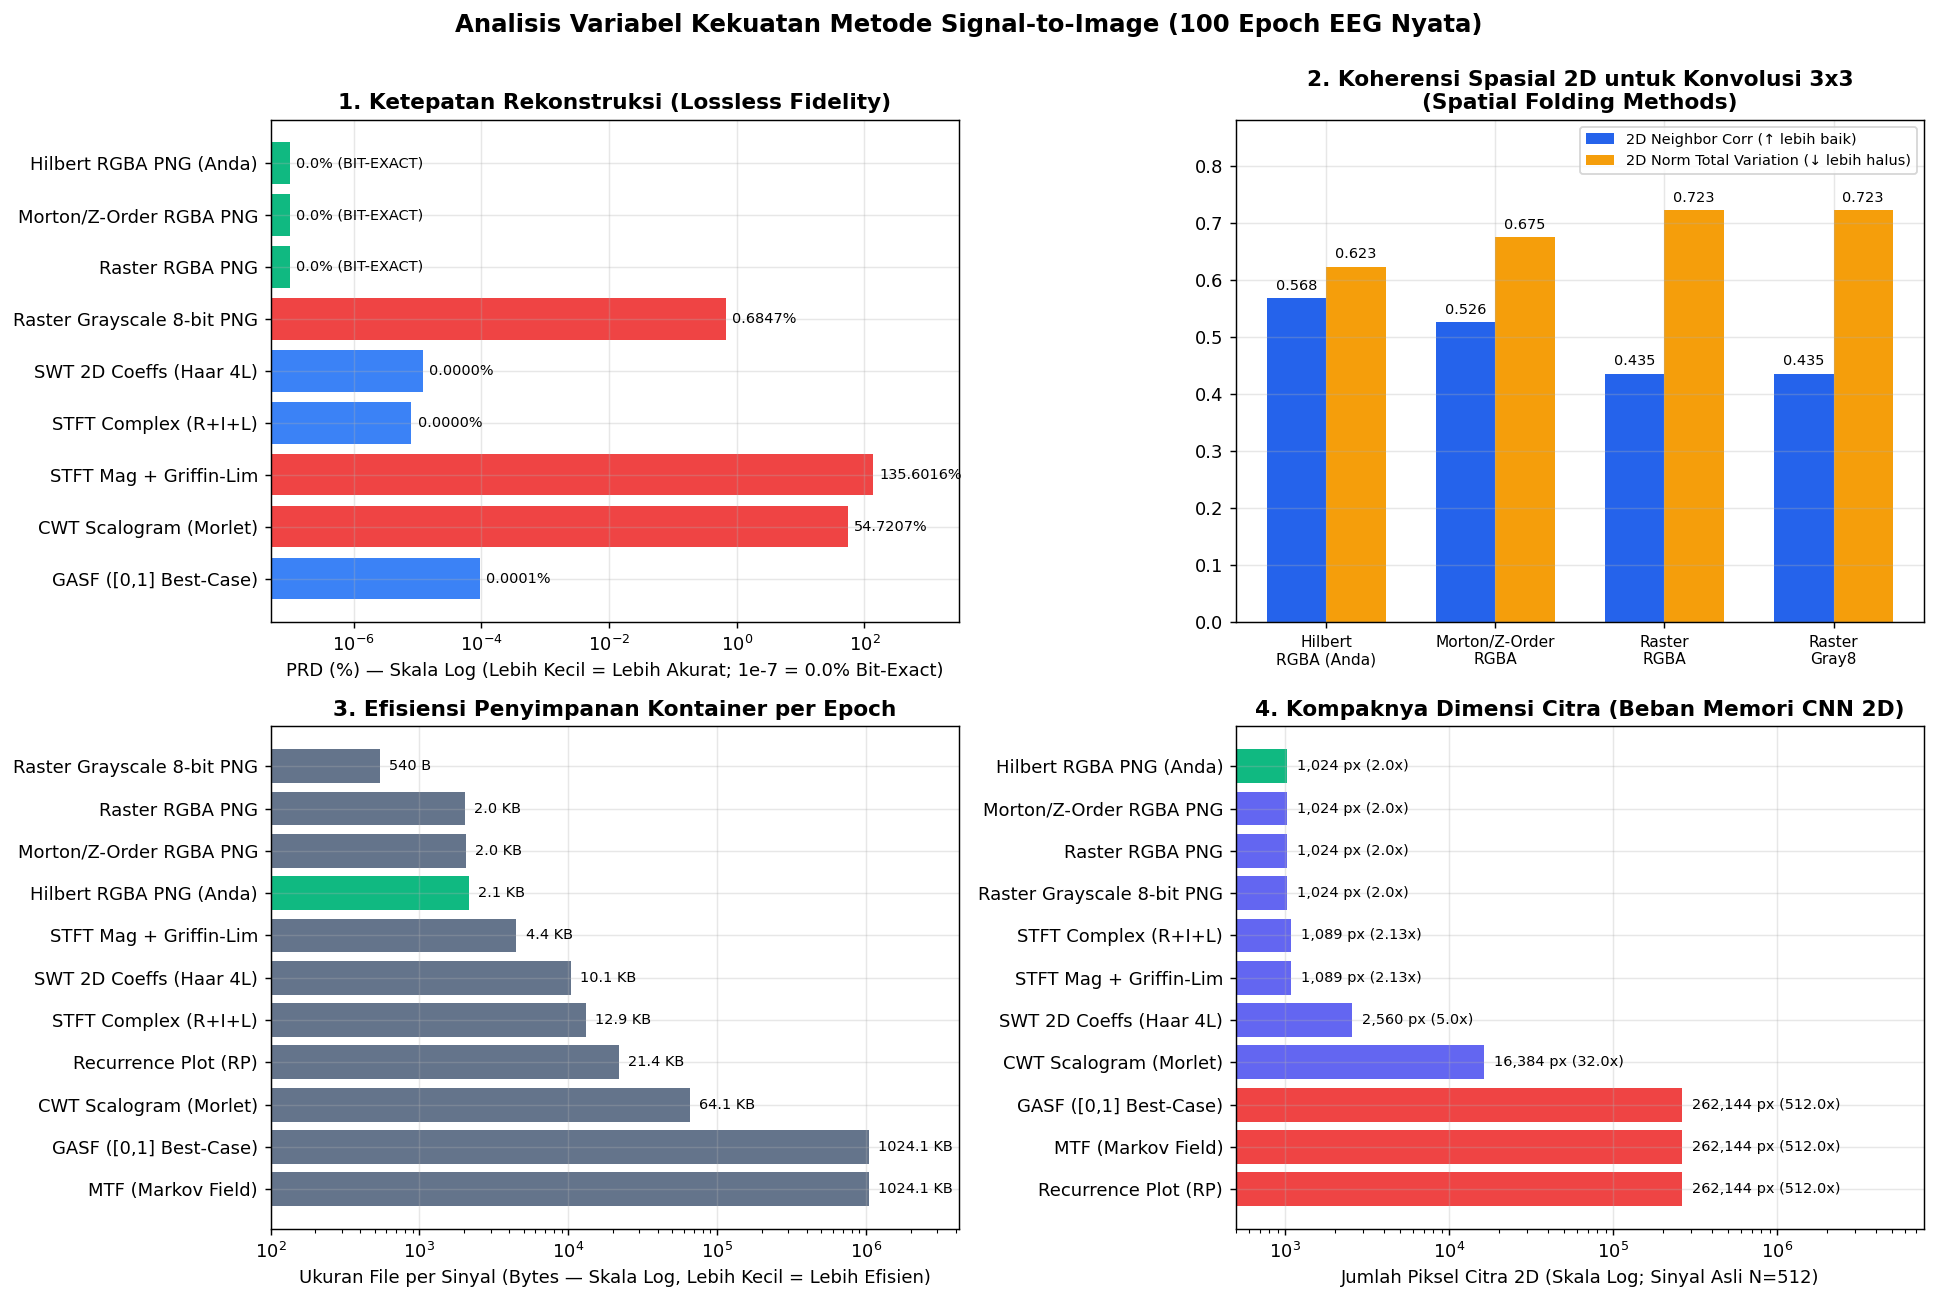

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), dpi=130)

# Panel 1: PRD (%) Rekonstruksi
ax = axes[0, 0]
inv_df = df[df["Mean_PRD_Pct"].notna()].copy()
prd_vals = np.maximum(inv_df["Mean_PRD_Pct"].to_numpy(), 1e-7)
colors1 = [
    "#10b981" if b == 100.0 else ("#3b82f6" if p < 1e-3 else "#ef4444")
    for b, p in zip(inv_df["Bit_Exact_Pct"], inv_df["Mean_PRD_Pct"])
]
bars = ax.barh(inv_df["Method"], prd_vals, color=colors1)
ax.set_xscale("log")
ax.set_xlim(5e-8, 3000)
ax.invert_yaxis()
ax.set_xlabel("PRD (%) — Skala Log (Lebih Kecil = Lebih Akurat; 1e-7 = 0.0% Bit-Exact)")
ax.set_title("1. Ketepatan Rekonstruksi (Lossless Fidelity)", fontweight="bold")
for bar, orig_v, bit_ex in zip(bars, inv_df["Mean_PRD_Pct"], inv_df["Bit_Exact_Pct"]):
    label = "0.0% (BIT-EXACT)" if bit_ex == 100.0 else f"{orig_v:.4f}%"
    ax.text(bar.get_width() * 1.25, bar.get_y() + bar.get_height() / 2, label, va="center", fontsize=8)
ax.grid(axis="x", alpha=0.3)

# Panel 2: Koherensi Spasial 2D (Spatial Folding)
ax = axes[0, 1]
sfc_df = df[df["Curve_Mean_Step_L1"].notna()].copy()
x = np.arange(len(sfc_df))
w = 0.35
b1 = ax.bar(x - w / 2, sfc_df["Spatial_Neighbor_Corr_2D"], width=w, label="2D Neighbor Corr (↑ lebih baik)", color="#2563eb")
b2 = ax.bar(x + w / 2, sfc_df["Spatial_Norm_TV_2D"], width=w, label="2D Norm Total Variation (↓ lebih halus)", color="#f59e0b")
ax.set_xticks(x)
ax.set_xticklabels(
    [m.replace(" RGBA PNG", "\nRGBA").replace(" Grayscale 8-bit PNG", "\nGray8") for m in sfc_df["Method"]],
    fontsize=8.5,
)
ax.set_title("2. Koherensi Spasial 2D untuk Konvolusi 3x3\n(Spatial Folding Methods)", fontweight="bold")
ax.legend(fontsize=8)
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, f"{bar.get_height():.3f}", ha="center", fontsize=8)
ax.set_ylim(0, max(sfc_df["Spatial_Neighbor_Corr_2D"].max(), sfc_df["Spatial_Norm_TV_2D"].max()) * 1.22)
ax.grid(axis="y", alpha=0.3)

# Panel 3: Ukuran File di Disk
ax = axes[1, 0]
disk_df = df.sort_values("Mean_Disk_Bytes")
colors3 = ["#10b981" if "Hilbert" in m else "#64748b" for m in disk_df["Method"]]
bars3 = ax.barh(disk_df["Method"], disk_df["Mean_Disk_Bytes"], color=colors3)
ax.set_xscale("log")
ax.invert_yaxis()
ax.set_xlabel("Ukuran File per Sinyal (Bytes — Skala Log, Lebih Kecil = Lebih Efisien)")
ax.set_title("3. Efisiensi Penyimpanan Kontainer per Epoch", fontweight="bold")
for bar, v in zip(bars3, disk_df["Mean_Disk_Bytes"]):
    txt = f"{v/1024:.1f} KB" if v >= 1024 else f"{v:.0f} B"
    ax.text(bar.get_width() * 1.15, bar.get_y() + bar.get_height() / 2, txt, va="center", fontsize=8)
ax.set_xlim(100, disk_df["Mean_Disk_Bytes"].max() * 4)
ax.grid(axis="x", alpha=0.3)

# Panel 4: Ekspansi Piksel 2D
ax = axes[1, 1]
pix_df = df.sort_values("Pixels_2D")
colors4 = [
    "#10b981" if "Hilbert" in m else ("#ef4444" if p > 50000 else "#6366f1")
    for m, p in zip(pix_df["Method"], pix_df["Pixels_2D"])
]
bars4 = ax.barh(pix_df["Method"], pix_df["Pixels_2D"], color=colors4)
ax.set_xscale("log")
ax.invert_yaxis()
ax.set_xlabel("Jumlah Piksel Citra 2D (Skala Log; Sinyal Asli N=512)")
ax.set_title("4. Kompaknya Dimensi Citra (Beban Memori CNN 2D)", fontweight="bold")
for bar, v, r in zip(bars4, pix_df["Pixels_2D"], pix_df["Expansion_Ratio_vs_N"]):
    ax.text(bar.get_width() * 1.15, bar.get_y() + bar.get_height() / 2, f"{v:,} px ({r}x)", va="center", fontsize=8)
ax.set_xlim(500, pix_df["Pixels_2D"].max() * 30)
ax.grid(axis="x", alpha=0.3)

plt.suptitle("Analisis Variabel Kekuatan Metode Signal-to-Image (100 Epoch EEG Nyata)", fontsize=13.5, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(OUT_DIR / "metrics_comparison_chart.png", bbox_inches="tight")
plt.show()


## 6. Uji Panjang Dinamis (*Self-Contained Metadata*) & Analisis Variabel Paling Kuat

Di bawah ini dilakukan pengujian khusus panjang sinyal dinamis ($N \in \{150, 300, 512, 750\}$) pada **Hilbert RGBA PNG** untuk memastikan bahwa dimensi citra selalu tetap (`32x32x4`) dan rekonstruksinya tetap **100% Bit-Exact** tanpa memerlukan file metadata terpisah, diikuti ringkasan variabel terkuat di setiap kategori.


In [7]:
# Uji Panjang Dinamis pada Hilbert RGBA PNG
base_long_sig = np.concatenate([signals[0][1], signals[1][1]])  # panjang 1024
dyn_rows = []
for n_dyn in [150, 300, 512, 750, 1023]:
    sub_sig = base_long_sig[:n_dyn].astype(np.float32)
    buf = io.BytesIO()
    shp = encode_hilbert_png(sub_sig, buf, img_size=32)
    rec = decode_hilbert_png(buf)
    m = eval_reconstruction_metrics(sub_sig, rec)
    dyn_rows.append({
        "Input_Length_N": n_dyn,
        "PNG_Shape": "x".join(map(str, shp)),
        "Decoded_Length": rec.size,
        "Bit_Exact": m["bit_exact"],
        "Max_Abs_Err": m["max_abs_err"],
        "PRD_Pct": m["prd_pct"],
        "PNG_Bytes": buf.getbuffer().nbytes,
    })

print("=== UJI PANJANG DINAMIS HILBERT RGBA PNG (SELF-CONTAINED METADATA) ===")
display(pd.DataFrame(dyn_rows))

# Ringkasan Variabel Pemenang
print("=" * 90)
print("ANALISIS VARIABEL PEMENANG (VARIABEL MANA YANG PALING KUAT?)")
print("=" * 90)

bit_exact_methods = df[df["Bit_Exact_Pct"] == 100.0]["Method"].tolist()
print(f"1. [LOSSLESS BIT-EXACT (Error = 0.0, PRD = 0.0%, SNR = inf)]:")
print(f"   Pemenang: {', '.join(bit_exact_methods)}")

sfc = df[df["Curve_Mean_Step_L1"].notna()]
best_step = sfc.loc[sfc["Curve_Mean_Step_L1"].idxmin()]
best_corr = sfc.loc[sfc["Spatial_Neighbor_Corr_2D"].idxmax()]
best_tv = sfc.loc[sfc["Spatial_Norm_TV_2D"].idxmin()]
raster_corr = sfc.loc[sfc["Method"] == "Raster RGBA PNG", "Spatial_Neighbor_Corr_2D"].values[0]
gain_pct = (best_corr["Spatial_Neighbor_Corr_2D"] - raster_corr) / raster_corr * 100.0

print(f"\n2. [LOKALITAS TEMPORAL -> SPASIAL 2D (Kunci Performa CNN/U-Net 2D)]:")
print(f"   • Jarak Langkah Temporal Terkecil : {best_step['Method']} (Mean L1 = {best_step['Curve_Mean_Step_L1']:.3f}, Max Jump = {int(best_step['Curve_Max_Jump_L1'])})")
print(f"   • Korelasi Tetangga 2D Tertinggi  : {best_corr['Method']} (r_2D = {best_corr['Spatial_Neighbor_Corr_2D']:.4f}, +{gain_pct:.1f}% vs Raster)")
print(f"   • Kehalusan Spasial (TV Terendah) : {best_tv['Method']} (Norm TV = {best_tv['Spatial_Norm_TV_2D']:.4f})")

best_pix = df.loc[df["Pixels_2D"].idxmin()]
best_disk_lossless = df[df["Bit_Exact_Pct"] == 100.0].sort_values("Mean_Disk_Bytes").iloc[0]
print(f"\n3. [EFISIENSI DIMENSI & PENYIMPANAN]:")
print(f"   • Dimensi Paling Kompak           : {best_pix['Method']} ({best_pix['Pixels_2D']:,} px, ekspansi {best_pix['Expansion_Ratio_vs_N']}x vs GASF/MTF/RP 512x!)")
print(f"   • Kontainer Bit-Exact Terkecil    : {best_disk_lossless['Method']} ({best_disk_lossless['Mean_Disk_Bytes']:.1f} bytes PNG self-contained)")

inv_df = df[df["Mean_RoundTrip_ms"].notna()]
fastest = inv_df.loc[inv_df["Mean_RoundTrip_ms"].idxmin()]
hilbert_rt = df.loc[df["Method"] == "Hilbert RGBA PNG (Anda)", "Mean_RoundTrip_ms"].values[0]
print(f"\n4. [KECEPATAN ROUND-TRIP ENCODE + DECODE]:")
print(f"   • Tercepat (Invertible)           : {fastest['Method']} ({fastest['Mean_RoundTrip_ms']:.3f} ms/sinyal)")
print(f"   • Hilbert RGBA PNG                : {hilbert_rt:.3f} ms/sinyal ({1000.0/hilbert_rt:,.0f} sinyal/detik)")


=== UJI PANJANG DINAMIS HILBERT RGBA PNG (SELF-CONTAINED METADATA) ===


,Input_Length_N,PNG_Shape,Decoded_Length,Bit_Exact,Max_Abs_Err,PRD_Pct,PNG_Bytes
0,150,32x32x4,150,True,0.0,0.0,761
1,300,32x32x4,300,True,0.0,0.0,1333
2,512,32x32x4,512,True,0.0,0.0,2104
3,750,32x32x4,750,True,0.0,0.0,2959
4,1023,32x32x4,1023,True,0.0,0.0,3885


ANALISIS VARIABEL PEMENANG (VARIABEL MANA YANG PALING KUAT?)
1. [LOSSLESS BIT-EXACT (Error = 0.0, PRD = 0.0%, SNR = inf)]:
   Pemenang: Hilbert RGBA PNG (Anda), Morton/Z-Order RGBA PNG, Raster RGBA PNG

2. [LOKALITAS TEMPORAL -> SPASIAL 2D (Kunci Performa CNN/U-Net 2D)]:
   • Jarak Langkah Temporal Terkecil : Hilbert RGBA PNG (Anda) (Mean L1 = 1.000, Max Jump = 1)
   • Korelasi Tetangga 2D Tertinggi  : Hilbert RGBA PNG (Anda) (r_2D = 0.5677, +30.4% vs Raster)
   • Kehalusan Spasial (TV Terendah) : Hilbert RGBA PNG (Anda) (Norm TV = 0.6234)

3. [EFISIENSI DIMENSI & PENYIMPANAN]:
   • Dimensi Paling Kompak           : Hilbert RGBA PNG (Anda) (1,024 px, ekspansi 2.0x vs GASF/MTF/RP 512x!)
   • Kontainer Bit-Exact Terkecil    : Raster RGBA PNG (2017.2 bytes PNG self-contained)

4. [KECEPATAN ROUND-TRIP ENCODE + DECODE]:
   • Tercepat (Invertible)           : Raster Grayscale 8-bit PNG (0.367 ms/sinyal)
   • Hilbert RGBA PNG                : 0.509 ms/sinyal (1,965 sinyal/detik)


## 7. Kesimpulan Utama untuk Pembahasan Tesis / Paper

**Variabel terkuat dari `Hilbert RGBA PNG` bukanlah *lossless*-nya semata, melainkan kombinasi simultan dari 4 keunggulan kunci** yang tidak dimiliki secara bersamaan oleh metode lain:

1. **100% Bit-Exact Lossless (`PRD = 0.0%`, `Max Error = 0.0`)** — mengalahkan STFT Mag + Griffin-Lim, CWT Morlet, dan Raster Grayscale 8-bit PNG.
2. **Preservasi Lokalitas Temporal $\to$ Spasial Optimal (`Mean L1 = 1.000`, `Max Jump = 1`)** — membedakan Hilbert secara tegas dari sesama metode bit-exact (`Raster RGBA` memiliki `Max Jump = 32` dan `Morton RGBA` memiliki `Max Jump = 16`), menghasilkan korelasi tetangga 2D **~30% lebih tinggi dibanding Raster** untuk konvolusi `3x3`.
3. **Dimensi Sangat Kompak (`32x32` = `1,024` piksel, `~2.15 KB` PNG)** — **256× lebih sedikit piksel** dan **~488× lebih hemat penyimpanan** dibanding GASF/MTF ($512\times 512$, `1.05 MB`).
4. **Self-Contained Dynamic Length Container** — mendukung panjang sinyal dinamis $N \in [1, 1023]$ pada dimensi citra tetap `32x32x4` tanpa file metadata terpisah.
